# Notebook 01 — EDA : Exploration des Données
## Moteur de Stress Testing IFRS 9 — Lending Club 2007-2018

**Objectif :** Explorer le dataset (2,26M prêts) pour comprendre la structure du risque de crédit,
identifier la relation macro-défaut et préparer les décisions de preprocessing.

| Section | Contenu |
|---|---|
| 1. Chargement | loan.csv (chunked) + variables macro FRED |
| 2. Vue d'ensemble | Taille, types, distribution `loan_status` |
| 3. Valeurs manquantes | Analyse des NaN, stratégie d'imputation |
| 4. Risque par segment | Grade, durée, purpose, logement, emploi |
| 5. Analyse temporelle | Crise 2008 — pic de défaut |
| 6. Distributions | `int_rate`, `dti`, `annual_inc`, `revol_util` |
| 7. Corrélations | Matrice features ↔ `default_flag` |
| 8. Variables macro | Cycle de crédit, UNRATE ↔ défauts |
| 9. Analyse LGD | Distribution LGD empirique par grade |

> **Note :** Ce notebook est purement analytique — aucune transformation permanente.
> Le preprocessing complet est dans le Notebook 02.

## Positionnement bancaire du notebook

**Role dans la plateforme**  
Comprendre le portefeuille, la qualite des donnees, les defauts, les vintages et les variables utiles avant toute modelisation.

**Lecture expert bancaire**  
Une banque commence par une photographie fiable du portefeuille: population, defauts, maturite, censure, distributions et anomalies.

**Sorties attendues**  
schema_quality_report, missing_by_year, vintage_default_profile, figures EDA.

**Transition logique**  
Le notebook 02 transforme cette exploration en dataset propre, datable et utilisable pour IFRS 9.

In [1]:
import sys
sys.path.insert(0, '..')

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')
PALETTE = sns.color_palette('RdYlGn_r', 7)

DATA_DIR  = Path('../data')
OUTPUT_DIR = Path('../outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

print('Imports OK')

Imports OK


---
## 1. Chargement des données

In [2]:
from src.data_prep import load_loan_data, load_macro_data, LOAN_COLS

# Lecture chunked — ne charge que les colonnes utiles
df_raw = load_loan_data(DATA_DIR / 'loan.csv')
macro  = load_macro_data()

print(f'\nPortefeuille : {df_raw.shape}')
print(f'Macro        : {macro.shape}')
print(f'\nMémoire utilisée : {df_raw.memory_usage(deep=True).sum() / 1e6:.0f} Mo')
print(f'\nColonnes chargées :')
print(list(df_raw.columns))

[load_loan_data] 2,260,668 lignes × 31 colonnes chargées
[load_macro_data] 315 points mensuels, colonnes : ['UNRATE', 'FEDFUNDS', 'CPI', 'GDPC1', 'GDP', 'DRCCLACBS', 'HY_SPREAD', 'GDPC1_growth', 'CPI_change']

Portefeuille : (2260668, 31)
Macro        : (315, 9)

Mémoire utilisée : 758 Mo

Colonnes chargées :
['loan_amnt', 'funded_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'purpose', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'out_prncp', 'total_pymnt', 'total_rec_prncp', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'acc_now_delinq', 'chargeoff_within_12_mths', 'hardship_flag']


---
## 2. Vue d'ensemble du portefeuille

In [3]:
# Types de données et statistiques rapides
print('=== Types de données ===')
print(df_raw.dtypes.value_counts())
print(f'\n{df_raw.shape[0]:,} prêts, {df_raw.shape[1]} colonnes')
print(f'\nPremières lignes :')
df_raw.head(3)

=== Types de données ===
float64    16
str        12
int64       3
Name: count, dtype: int64

2,260,668 prêts, 31 colonnes

Premières lignes :


,loan_amnt,funded_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,...,total_acc,out_prncp,total_pymnt,total_rec_prncp,recoveries,collection_recovery_fee,last_pymnt_d,acc_now_delinq,chargeoff_within_12_mths,hardship_flag
0,2500,2500,36 months,13.56,84.92,C,C1,10+ years,RENT,55000.0,...,34.0,2386.02,167.02,113.98,0.0,0.0,Feb-2019,0.0,0.0,N
1,30000,30000,60 months,18.94,777.23,D,D2,10+ years,MORTGAGE,90000.0,...,44.0,29387.75,1507.11,612.25,0.0,0.0,Feb-2019,0.0,0.0,N
2,5000,5000,36 months,17.97,180.69,D,D1,6 years,MORTGAGE,59280.0,...,13.0,4787.21,353.89,212.79,0.0,0.0,Feb-2019,0.0,0.0,N


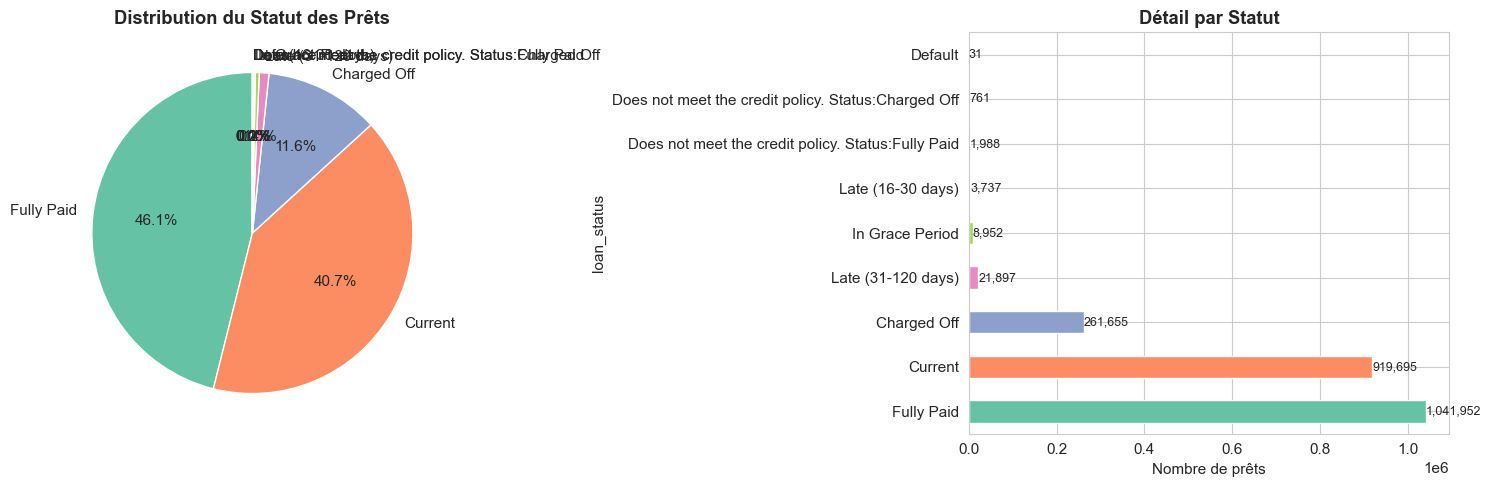


Taux de défaut global : 11.61% (262,447 prêts)


In [4]:
# Distribution loan_status
DEFAULT_STATUS = {'Default', 'Charged Off',
                  'Does not meet the credit policy. Status:Charged Off'}

status_counts = df_raw['loan_status'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].pie(status_counts, labels=status_counts.index,
            autopct='%1.1f%%', startangle=90,
            colors=sns.color_palette('Set2', len(status_counts)))
axes[0].set_title('Distribution du Statut des Prêts', fontweight='bold')

status_counts.plot(kind='barh', ax=axes[1],
                   color=sns.color_palette('Set2', len(status_counts)))
axes[1].set_xlabel('Nombre de prêts')
axes[1].set_title('Détail par Statut', fontweight='bold')
for i, v in enumerate(status_counts):
    axes[1].text(v + 100, i, f'{v:,}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_01_loan_status.png', dpi=150, bbox_inches='tight')
plt.show()

df_raw['default_flag'] = df_raw['loan_status'].isin(DEFAULT_STATUS).astype(int)
print(f'\nTaux de défaut global : {df_raw["default_flag"].mean():.2%} ({df_raw["default_flag"].sum():,} prêts)')

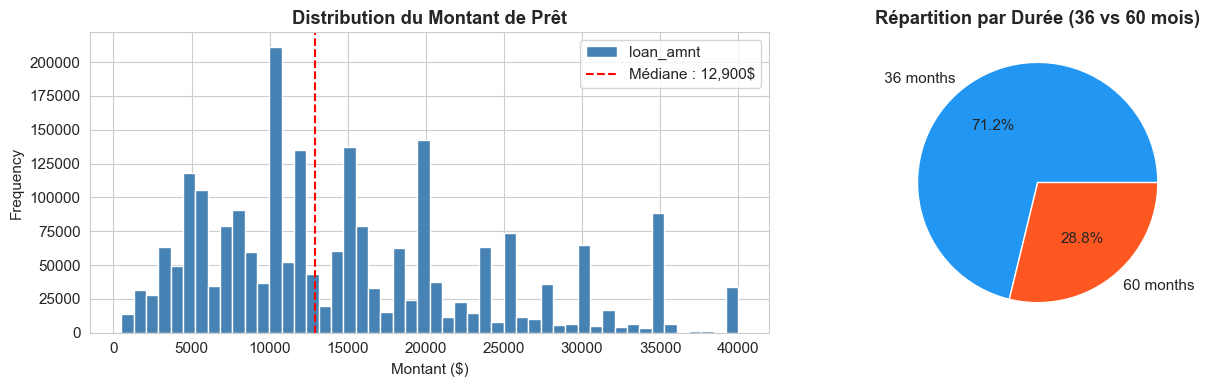

Montant moyen    : $15,047
Montant médian   : $12,900
Montant max      : $40,000


In [5]:
# Distribution des montants de prêts et répartition durée
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df_raw['loan_amnt'].plot(kind='hist', bins=50, ax=axes[0],
                          color='steelblue', edgecolor='white')
axes[0].set_title('Distribution du Montant de Prêt', fontweight='bold')
axes[0].set_xlabel('Montant ($)')
axes[0].axvline(df_raw['loan_amnt'].median(), color='red', linestyle='--',
                label=f"Médiane : {df_raw['loan_amnt'].median():,.0f}$")
axes[0].legend()

term_counts = df_raw['term'].value_counts()
axes[1].pie(term_counts, labels=term_counts.index, autopct='%1.1f%%',
            colors=['#2196F3', '#FF5722'])
axes[1].set_title('Répartition par Durée (36 vs 60 mois)', fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_02_loan_amnt.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Montant moyen    : ${df_raw['loan_amnt'].mean():,.0f}")
print(f"Montant médian   : ${df_raw['loan_amnt'].median():,.0f}")
print(f"Montant max      : ${df_raw['loan_amnt'].max():,.0f}")

---
## 3. Analyse des valeurs manquantes

=== Colonnes avec données manquantes ===
emp_length      6.5
last_pymnt_d    0.1
revol_util      0.1
dti             0.1


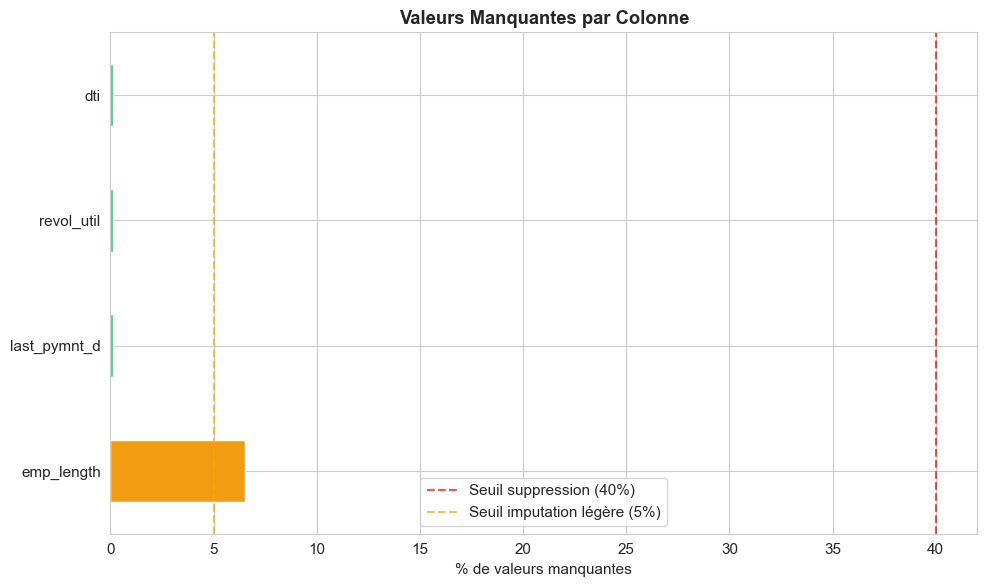


Colonnes à forte proportion de NaN (>40%) : 0
[]


In [6]:
missing = df_raw.isnull().mean().sort_values(ascending=False)
missing_pct = (missing * 100).round(1)

print('=== Colonnes avec données manquantes ===')
print(missing_pct[missing_pct > 0].to_string())

fig, ax = plt.subplots(figsize=(10, 6))
missing_plot = missing_pct[missing_pct > 0].head(25)
colors = ['#e74c3c' if v > 40 else '#f39c12' if v > 5 else '#2ecc71'
          for v in missing_plot]
missing_plot.plot(kind='barh', ax=ax, color=colors)
ax.axvline(40, color='red', linestyle='--', alpha=0.7, label='Seuil suppression (40%)')
ax.axvline(5, color='orange', linestyle='--', alpha=0.7, label='Seuil imputation légère (5%)')
ax.set_xlabel('% de valeurs manquantes')
ax.set_title('Valeurs Manquantes par Colonne', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_03_missing_values.png', dpi=150, bbox_inches='tight')
plt.show()

cols_high_nan = missing_pct[missing_pct > 40].index.tolist()
print(f'\nColonnes à forte proportion de NaN (>40%) : {len(cols_high_nan)}')
print(cols_high_nan)

---
## 4. Analyse du risque de crédit par segment

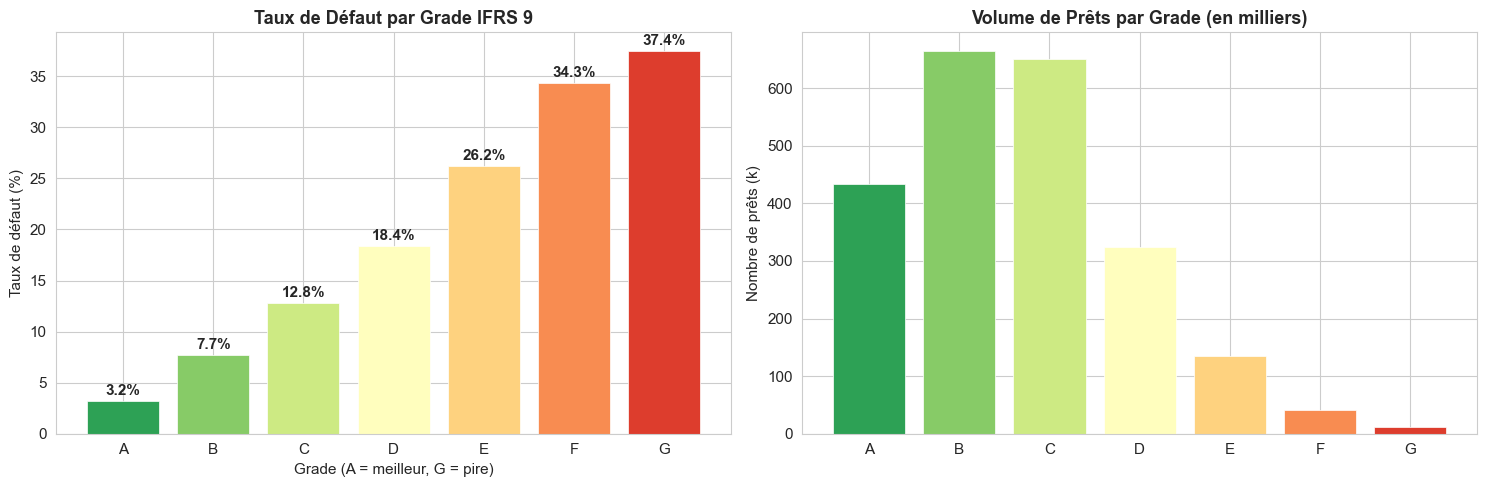


Taux de défaut par grade :
grade
A     3.18
B     7.71
C    12.83
D    18.39
E    26.19
F    34.35
G    37.43
Name: default_rate, dtype: float64


In [7]:
# 4.1 Taux de défaut par grade
dr_grade = df_raw.groupby('grade')['default_flag'].agg(['mean', 'count'])
dr_grade.columns = ['default_rate', 'count']
dr_grade = dr_grade.reindex(['A','B','C','D','E','F','G'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

bars = axes[0].bar(dr_grade.index, dr_grade['default_rate'] * 100,
                    color=PALETTE, edgecolor='white', linewidth=0.5)
axes[0].set_title('Taux de Défaut par Grade IFRS 9', fontweight='bold', fontsize=13)
axes[0].set_ylabel('Taux de défaut (%)')
axes[0].set_xlabel('Grade (A = meilleur, G = pire)')
for bar, val in zip(bars, dr_grade['default_rate']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1%}', ha='center', va='bottom', fontweight='bold')

axes[1].bar(dr_grade.index, dr_grade['count'] / 1000, color=PALETTE,
            edgecolor='white', linewidth=0.5)
axes[1].set_title('Volume de Prêts par Grade (en milliers)', fontweight='bold', fontsize=13)
axes[1].set_ylabel('Nombre de prêts (k)')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_04_default_by_grade.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nTaux de défaut par grade :')
print((dr_grade['default_rate'] * 100).round(2))

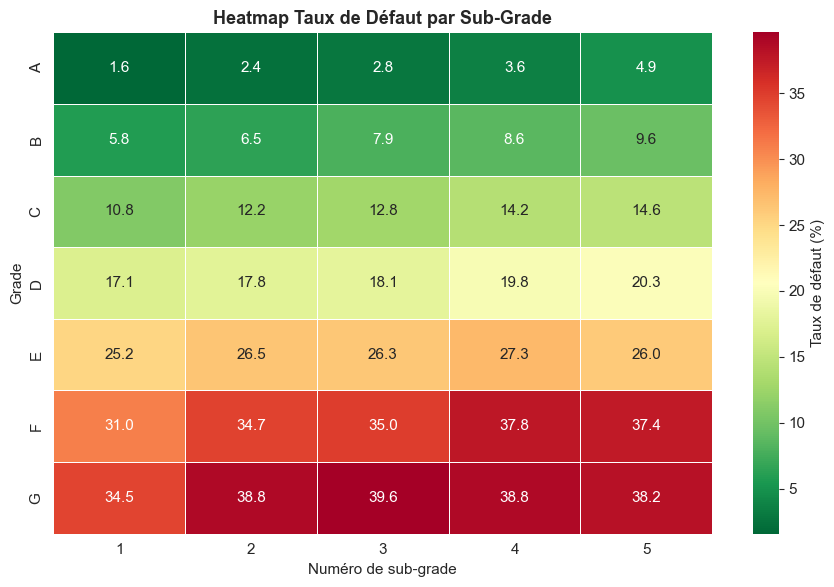

In [8]:
# 4.2 Heatmap taux de défaut par sub_grade (matrice 7x5)
if 'sub_grade' in df_raw.columns:
    dr_sub = df_raw.groupby('sub_grade')['default_flag'].mean()
    grades = list('ABCDEFG')
    subgrades_matrix = pd.DataFrame(index=grades, columns=[1,2,3,4,5], dtype=float)
    for g in grades:
        for n in range(1, 6):
            key = f'{g}{n}'
            if key in dr_sub.index:
                subgrades_matrix.loc[g, n] = dr_sub[key]
    plt.figure(figsize=(9, 6))
    sns.heatmap(subgrades_matrix.astype(float) * 100, annot=True, fmt='.1f',
                cmap='RdYlGn_r', linewidths=0.5,
                cbar_kws={'label': 'Taux de défaut (%)'})
    plt.title('Heatmap Taux de Défaut par Sub-Grade', fontweight='bold', fontsize=13)
    plt.xlabel('Numéro de sub-grade')
    plt.ylabel('Grade')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_05_heatmap_subgrade.png', dpi=150, bbox_inches='tight')
    plt.show()

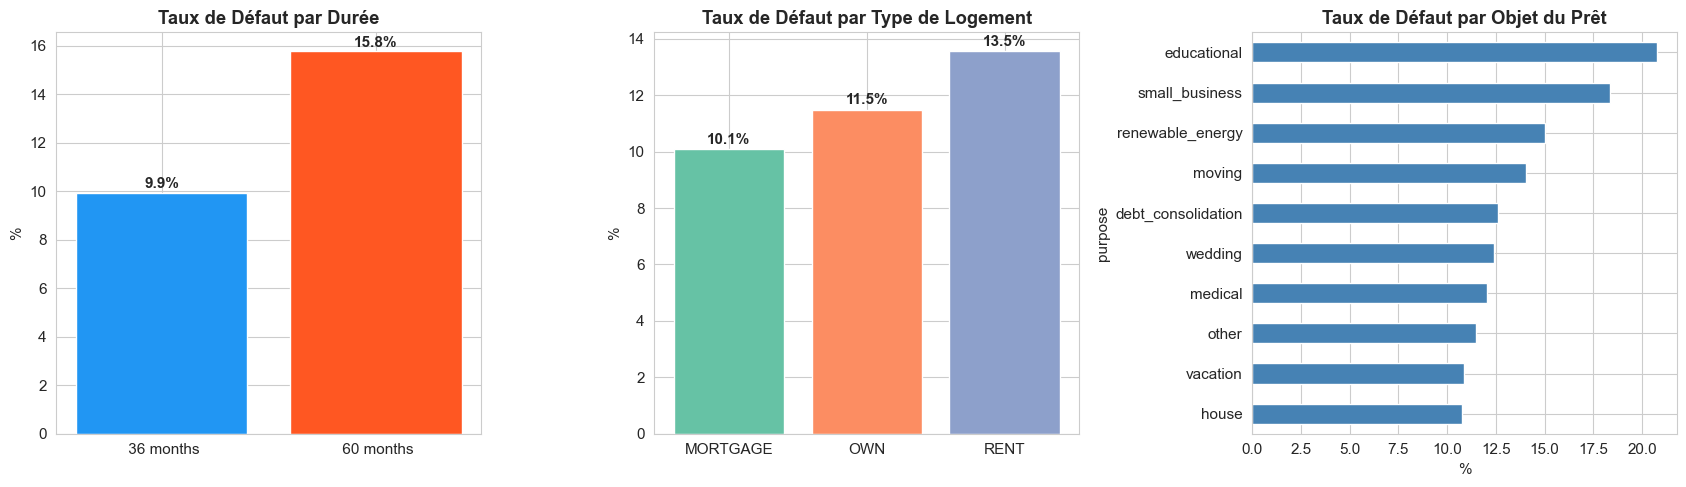

In [9]:
# 4.3 Défaut par durée, home_ownership et purpose
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Terme
dr_term = df_raw.groupby('term')['default_flag'].mean() * 100
axes[0].bar(range(len(dr_term)), dr_term.values, color=['#2196F3', '#FF5722'])
axes[0].set_xticks(range(len(dr_term)))
axes[0].set_xticklabels(dr_term.index)
axes[0].set_title('Taux de Défaut par Durée', fontweight='bold')
axes[0].set_ylabel('%')
for i, v in enumerate(dr_term):
    axes[0].text(i, v + 0.2, f'{v:.1f}%', ha='center', fontweight='bold')

# Home ownership
if 'home_ownership' in df_raw.columns:
    dr_ho = df_raw.groupby('home_ownership')['default_flag'].mean() * 100
    dr_ho = dr_ho[dr_ho.index.isin(['RENT', 'OWN', 'MORTGAGE'])]
    axes[1].bar(dr_ho.index, dr_ho, color=sns.color_palette('Set2', 3))
    axes[1].set_title('Taux de Défaut par Type de Logement', fontweight='bold')
    axes[1].set_ylabel('%')
    for i, (label, v) in enumerate(dr_ho.items()):
        axes[1].text(i, v + 0.2, f'{v:.1f}%', ha='center', fontweight='bold')

# Purpose (top 10)
if 'purpose' in df_raw.columns:
    dr_purpose = (df_raw.groupby('purpose')['default_flag'].mean() * 100)
    dr_purpose = dr_purpose.sort_values(ascending=True).tail(10)
    dr_purpose.plot(kind='barh', ax=axes[2], color='steelblue')
    axes[2].set_title('Taux de Défaut par Objet du Prêt', fontweight='bold')
    axes[2].set_xlabel('%')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_06_default_segments.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 5. Analyse temporelle — Crise 2008

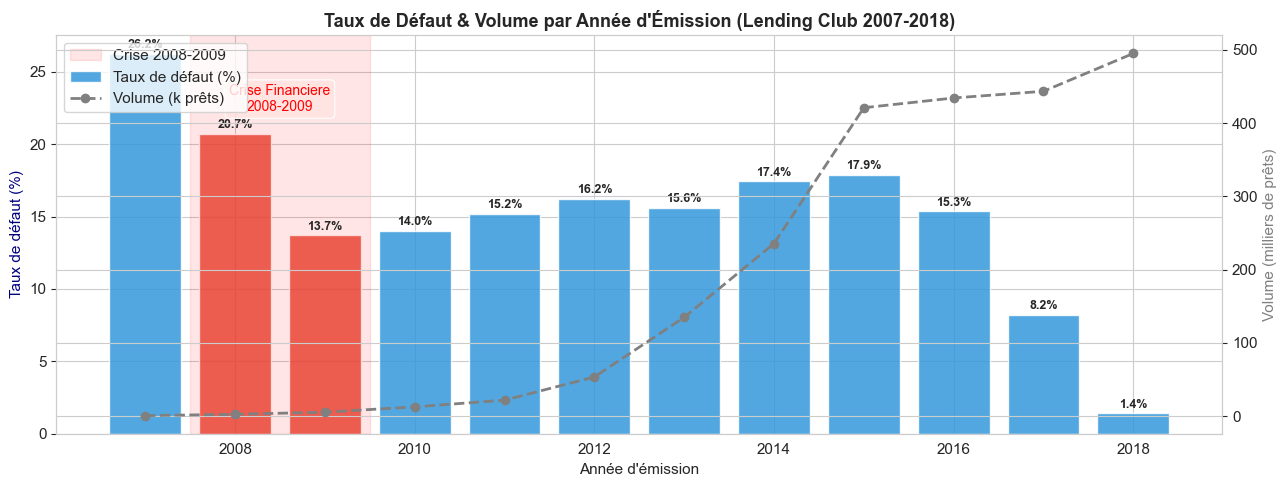


Taux de défaut par année :
year
2007    26.20
2008    20.73
2009    13.69
2010    14.01
2011    15.18
2012    16.20
2013    15.59
2014    17.42
2015    17.88
2016    15.35
2017     8.20
2018     1.40


In [10]:
df_raw['issue_d_dt'] = pd.to_datetime(df_raw['issue_d'], format='%b-%Y', errors='coerce')
df_raw['year'] = df_raw['issue_d_dt'].dt.year
df_raw['quarter'] = df_raw['issue_d_dt'].dt.to_period('Q')

dr_year = df_raw.groupby('year')['default_flag'].agg(['mean', 'count'])
dr_year.columns = ['default_rate', 'volume']
dr_year = dr_year.dropna()

fig, ax1 = plt.subplots(figsize=(13, 5))

color_bars = ['#e74c3c' if y in [2008, 2009] else '#3498db' for y in dr_year.index]
bars = ax1.bar(dr_year.index, dr_year['default_rate'] * 100,
               color=color_bars, alpha=0.85, label='Taux de défaut (%)')
ax1.set_xlabel("Année d'émission")
ax1.set_ylabel('Taux de défaut (%)', color='navy')

for bar, val in zip(bars, dr_year['default_rate']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f'{val:.1%}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(dr_year.index, dr_year['volume'] / 1000, 'o--', color='gray',
         linewidth=2, label='Volume (k prêts)')
ax2.set_ylabel('Volume (milliers de prêts)', color='gray')

ax1.axvspan(2007.5, 2009.5, alpha=0.1, color='red', label='Crise 2008-2009')
ax1.annotate('Crise Financiere\n2008-2009',
             xy=(2008.5, dr_year['default_rate'].max() * 100 * 0.85),
             fontsize=10, color='red', ha='center',
             bbox=dict(boxstyle='round', facecolor='mistyrose', alpha=0.8))

ax1.set_title("Taux de Défaut & Volume par Année d'Émission (Lending Club 2007-2018)",
               fontweight='bold', fontsize=13)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_07_default_over_time.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nTaux de défaut par année :')
print((dr_year['default_rate'] * 100).round(2).to_string())

## 5.b Analyse vintage et censure

Amelioration expert : les prets recents peuvent etre encore trop jeunes pour avoir defaulte. Cette cellule controle la maturite d'observation par annee d'emission avant de conclure sur le taux de defaut.


,year,loans,default_rate,obs_months_median,mature_12m_rate
0,2007,603,0.262023,32.985626,0.820896
1,2008,2393,0.207271,32.032854,0.833682
2,2009,5281,0.136906,30.981520,0.837909
3,2010,12537,0.140145,32.985626,0.846375
4,2011,21721,0.151789,32.000000,0.861056
5,2012,53367,0.161973,29.930185,0.837765
6,2013,134814,0.155933,27.958932,0.825322
7,2014,235629,0.174240,27.039014,0.807439
8,2015,421095,0.178760,27.039014,0.825460
9,2016,434407,0.153494,25.034908,0.779615


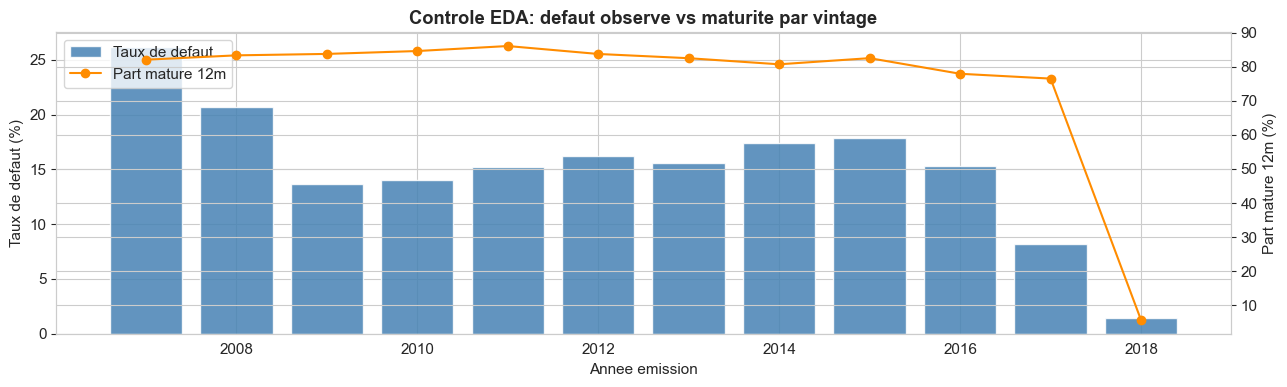

In [11]:
# Controle de censure temporelle par vintage
if 'last_pymnt_d' in df_raw.columns:
    df_raw['last_pymnt_d_dt'] = pd.to_datetime(df_raw['last_pymnt_d'], format='%b-%Y', errors='coerce')
    last_obs = df_raw['last_pymnt_d_dt'].fillna(df_raw['last_pymnt_d_dt'].max())
    df_raw['observation_months'] = ((last_obs - df_raw['issue_d_dt']).dt.days / 30.4375).clip(lower=0)
    df_raw['mature_12m_flag'] = (df_raw['observation_months'] >= 12).astype(int)

    vintage_profile = df_raw.groupby('year').agg(
        loans=('default_flag', 'count'),
        default_rate=('default_flag', 'mean'),
        obs_months_median=('observation_months', 'median'),
        mature_12m_rate=('mature_12m_flag', 'mean'),
    ).dropna().reset_index()

    display(vintage_profile.tail(12))
    vintage_profile.to_csv(OUTPUT_DIR / 'eda_vintage_censure_profile.csv', index=False)

    fig, ax1 = plt.subplots(figsize=(13, 4))
    ax1.bar(vintage_profile['year'], vintage_profile['default_rate'] * 100,
            color='steelblue', alpha=0.85, label='Taux de defaut')
    ax1.set_ylabel('Taux de defaut (%)')
    ax2 = ax1.twinx()
    ax2.plot(vintage_profile['year'], vintage_profile['mature_12m_rate'] * 100,
             color='darkorange', marker='o', label='Part mature 12m')
    ax2.set_ylabel('Part mature 12m (%)')
    ax1.set_title('Controle EDA: defaut observe vs maturite par vintage', fontweight='bold')
    ax1.set_xlabel('Annee emission')
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_07b_vintage_censure.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('last_pymnt_d indisponible: controle vintage/censure saute.')


---
## 6. Distributions des variables continues

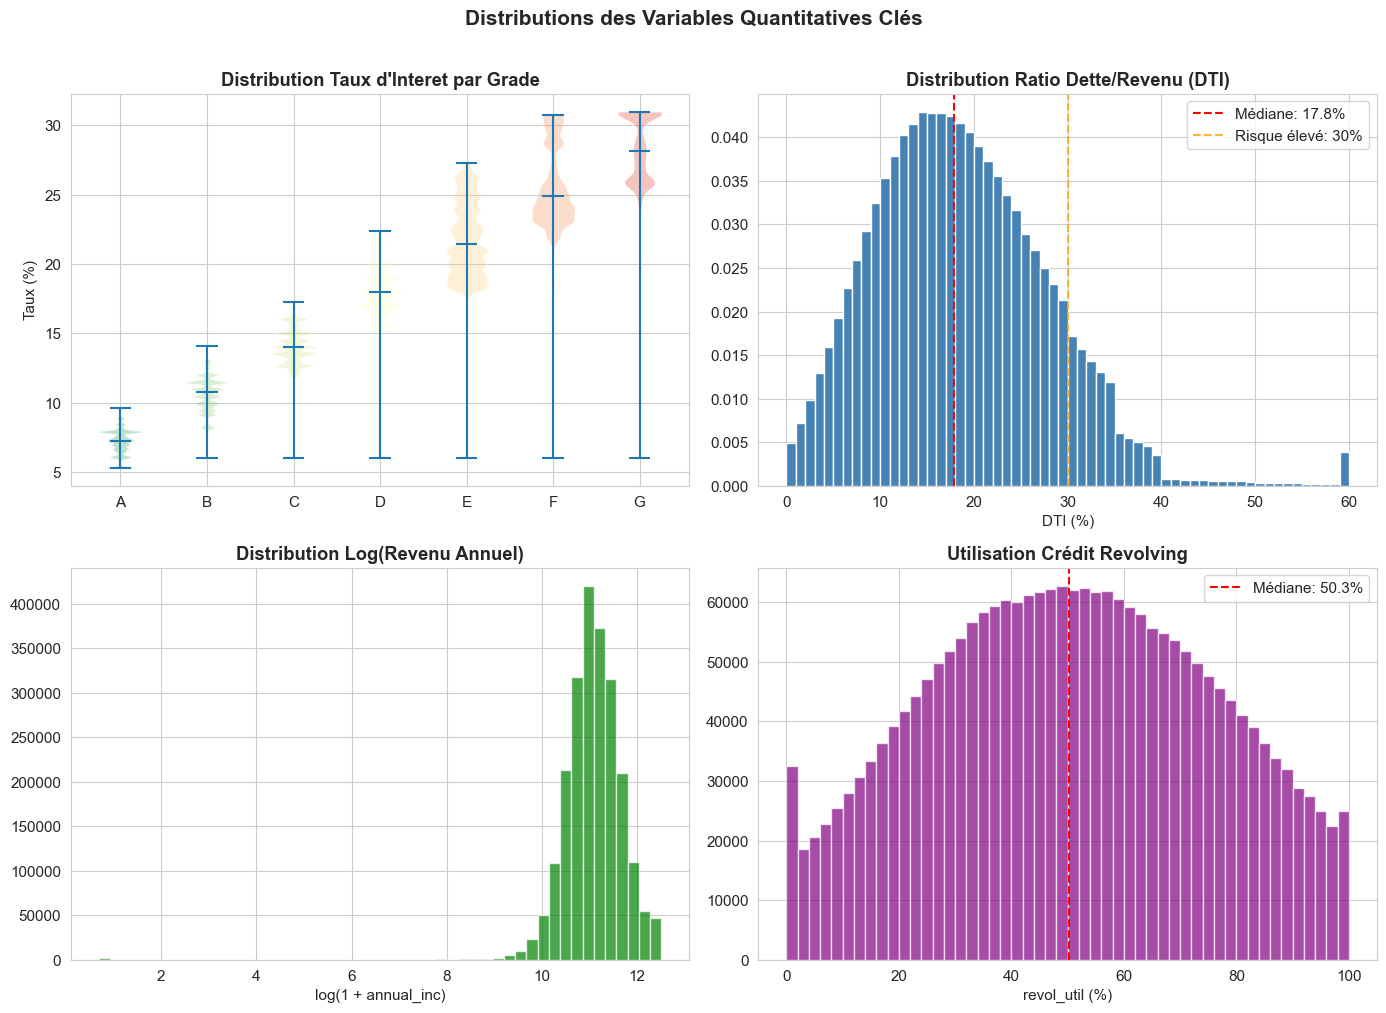

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# int_rate par grade — violin plot
if 'int_rate' in df_raw.columns:
    df_int = df_raw.copy()
    if df_int['int_rate'].dtype == object:
        df_int['int_rate'] = df_int['int_rate'].str.replace('%', '', regex=False).astype(float)
    grades_order = ['A','B','C','D','E','F','G']
    data_violin = [df_int[df_int['grade'] == g]['int_rate'].dropna() for g in grades_order]
    parts = axes[0,0].violinplot(data_violin, positions=range(7), showmedians=True)
    for i, pc in enumerate(parts['bodies']):
        pc.set_facecolor(PALETTE[i])
    axes[0,0].set_xticks(range(7))
    axes[0,0].set_xticklabels(grades_order)
    axes[0,0].set_title("Distribution Taux d'Interet par Grade", fontweight='bold')
    axes[0,0].set_ylabel('Taux (%)')

# DTI
if 'dti' in df_raw.columns:
    dti_clean = pd.to_numeric(df_raw['dti'], errors='coerce').dropna().clip(0, 60)
    axes[0,1].hist(dti_clean, bins=60, color='steelblue', edgecolor='white', density=True)
    axes[0,1].axvline(dti_clean.median(), color='red', linestyle='--',
                      label=f'Médiane: {dti_clean.median():.1f}%')
    axes[0,1].axvline(30, color='orange', linestyle='--', alpha=0.8, label='Risque élevé: 30%')
    axes[0,1].set_title('Distribution Ratio Dette/Revenu (DTI)', fontweight='bold')
    axes[0,1].set_xlabel('DTI (%)')
    axes[0,1].legend()

# Annual income (log)
if 'annual_inc' in df_raw.columns:
    inc_clean = pd.to_numeric(df_raw['annual_inc'], errors='coerce').dropna()
    inc_clean = inc_clean.clip(1, inc_clean.quantile(0.99))
    axes[1,0].hist(np.log1p(inc_clean), bins=50, color='green', edgecolor='white', alpha=0.7)
    axes[1,0].set_title('Distribution Log(Revenu Annuel)', fontweight='bold')
    axes[1,0].set_xlabel('log(1 + annual_inc)')

# Revol_util
if 'revol_util' in df_raw.columns:
    ru = pd.to_numeric(df_raw['revol_util'].astype(str).str.replace('%','',regex=False),
                       errors='coerce').clip(0, 100)
    axes[1,1].hist(ru.dropna(), bins=50, color='purple', edgecolor='white', alpha=0.7)
    axes[1,1].axvline(ru.median(), color='red', linestyle='--',
                      label=f'Médiane: {ru.median():.1f}%')
    axes[1,1].set_title('Utilisation Crédit Revolving', fontweight='bold')
    axes[1,1].set_xlabel('revol_util (%)')
    axes[1,1].legend()

plt.suptitle('Distributions des Variables Quantitatives Clés',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_08_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 7. Matrice de corrélation — Features vs default_flag

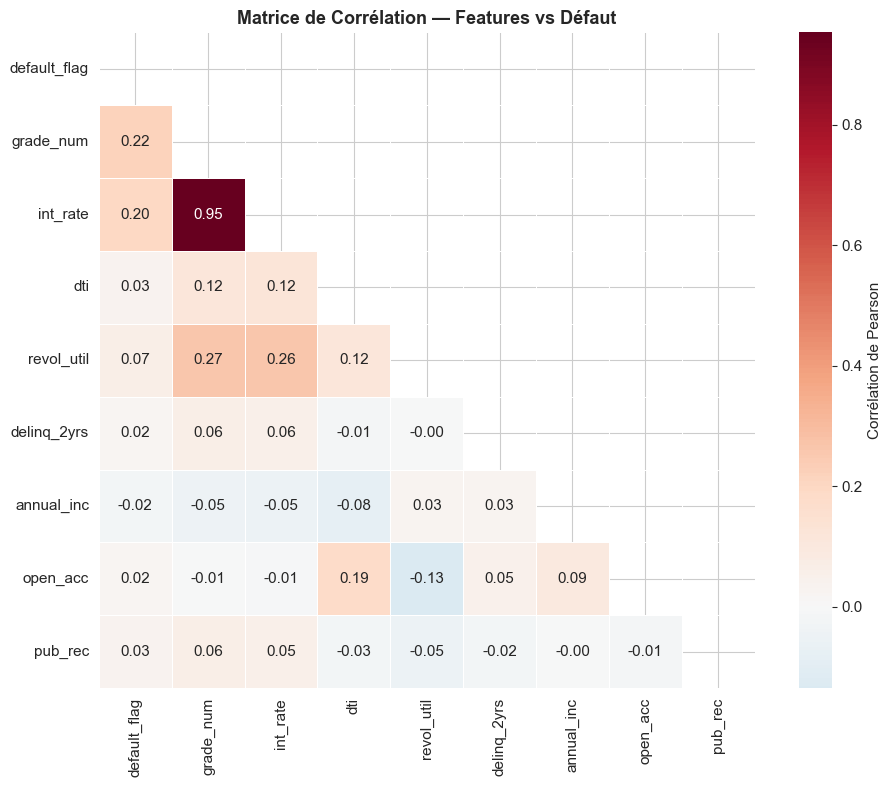


Top corrélations avec default_flag :
grade_num      0.221145
int_rate       0.196205
revol_util     0.066862
dti            0.033757
pub_rec        0.031335
annual_inc     0.024657
delinq_2yrs    0.018994
open_acc       0.018528


In [13]:
from src.data_prep import GRADE_MAP

df_corr = df_raw.copy()
df_corr['grade_num'] = df_corr['grade'].map(GRADE_MAP)

for col in ['int_rate', 'revol_util']:
    if col in df_corr.columns and df_corr[col].dtype == object:
        df_corr[col] = pd.to_numeric(
            df_corr[col].str.replace('%','',regex=False), errors='coerce'
        )

corr_cols = [c for c in ['default_flag', 'grade_num', 'int_rate', 'dti',
                          'revol_util', 'delinq_2yrs', 'annual_inc',
                          'open_acc', 'pub_rec'] if c in df_corr.columns]

corr = df_corr[corr_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            mask=mask, linewidths=0.5, square=True,
            cbar_kws={'label': 'Corrélation de Pearson'})
plt.title('Matrice de Corrélation — Features vs Défaut', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_09_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nTop corrélations avec default_flag :')
corr_with_default = corr['default_flag'].drop('default_flag').abs().sort_values(ascending=False)
print(corr_with_default.to_string())

---
## 8. Variables macro — Cycle de crédit

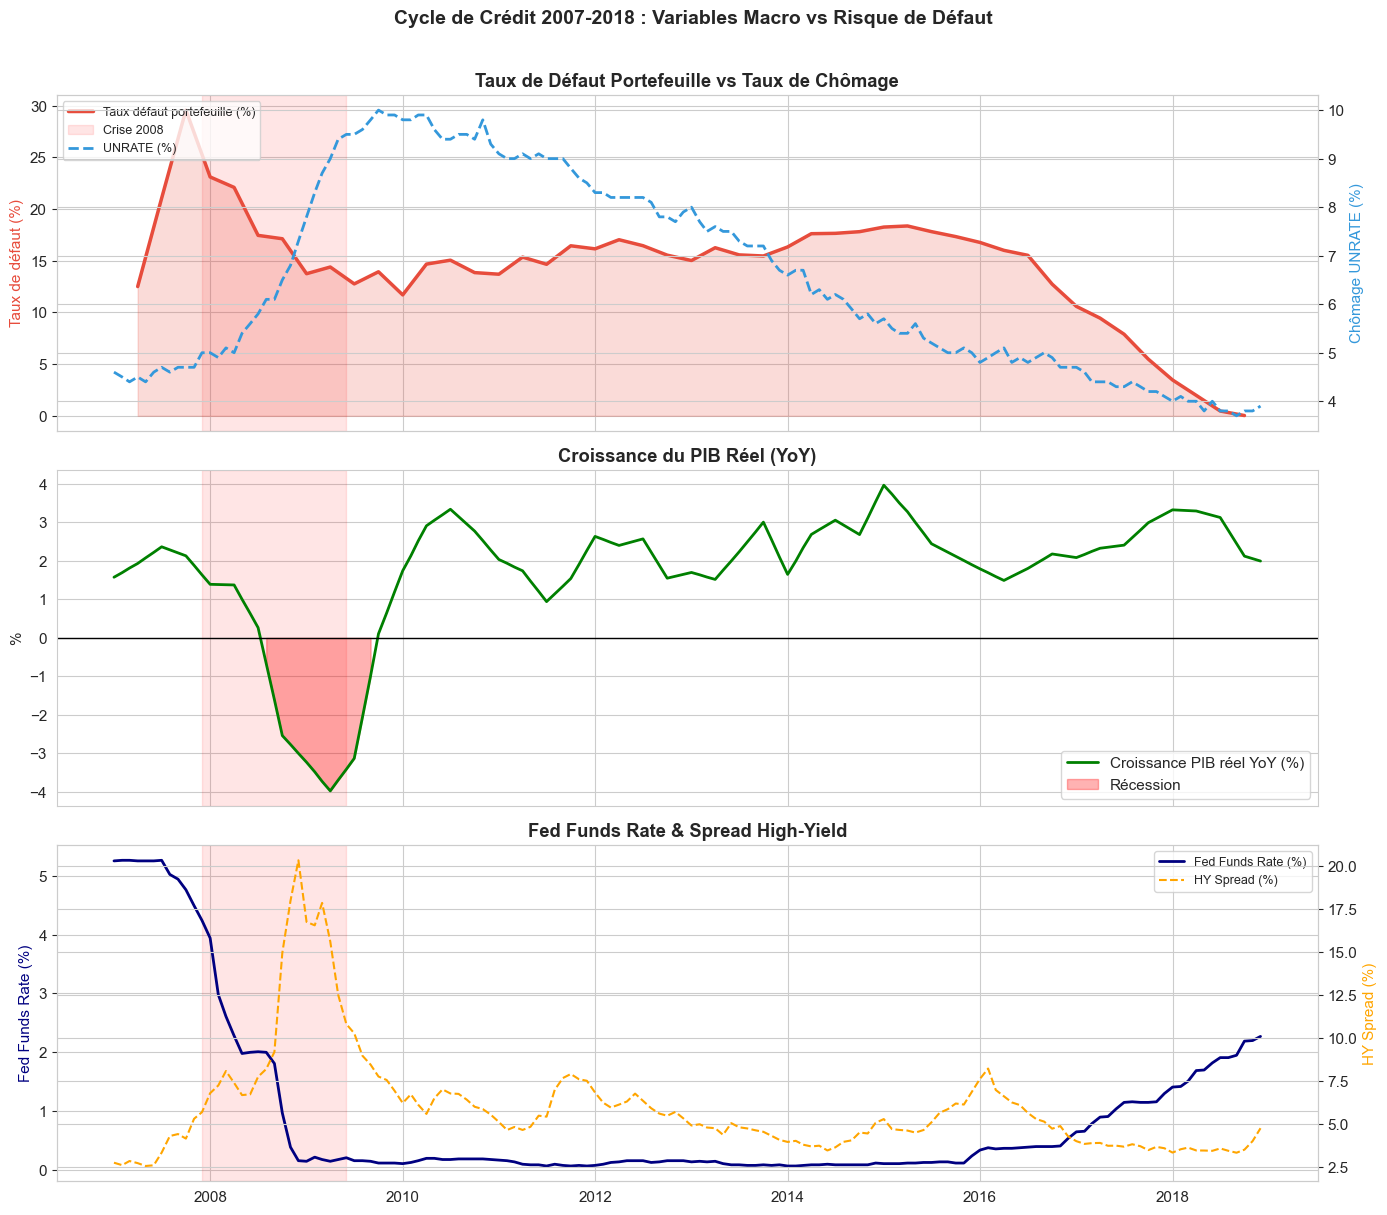

In [14]:
# Taux de défaut trimestriel du portefeuille
dr_quarterly = df_raw.groupby('quarter')['default_flag'].agg(['mean', 'count'])
dr_quarterly.columns = ['default_rate', 'count']
dr_quarterly.index = dr_quarterly.index.to_timestamp()

macro_plot = macro.loc['2007':'2018'].copy()

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Panel 1 : Taux de défaut vs UNRATE
ax1_twin = axes[0].twinx()
axes[0].plot(dr_quarterly.index, dr_quarterly['default_rate'] * 100,
             color='#e74c3c', linewidth=2.5, label='Taux défaut portefeuille (%)')
axes[0].set_ylabel('Taux de défaut (%)', color='#e74c3c')
axes[0].fill_between(dr_quarterly.index, dr_quarterly['default_rate'] * 100,
                      alpha=0.2, color='#e74c3c')
ax1_twin.plot(macro_plot.index, macro_plot['UNRATE'],
              color='#3498db', linewidth=2, linestyle='--', label='UNRATE (%)')
ax1_twin.set_ylabel('Chômage UNRATE (%)', color='#3498db')
axes[0].set_title('Taux de Défaut Portefeuille vs Taux de Chômage', fontweight='bold')
axes[0].axvspan(pd.Timestamp('2007-12-01'), pd.Timestamp('2009-06-01'),
                 alpha=0.1, color='red', label='Crise 2008')
lines1, labels1 = axes[0].get_legend_handles_labels()
lines2, labels2 = ax1_twin.get_legend_handles_labels()
axes[0].legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9)

# Panel 2 : PIB réel
axes[1].plot(macro_plot.index, macro_plot['GDPC1_growth'], color='green',
             linewidth=2, label='Croissance PIB réel YoY (%)')
axes[1].axhline(0, color='black', linewidth=1)
axes[1].fill_between(macro_plot.index, macro_plot['GDPC1_growth'], 0,
                      where=(macro_plot['GDPC1_growth'] < 0),
                      color='red', alpha=0.3, label='Récession')
axes[1].axvspan(pd.Timestamp('2007-12-01'), pd.Timestamp('2009-06-01'),
                 alpha=0.1, color='red')
axes[1].set_title('Croissance du PIB Réel (YoY)', fontweight='bold')
axes[1].set_ylabel('%')
axes[1].legend()

# Panel 3 : Fed Funds + HY Spread
ax3_twin = axes[2].twinx()
axes[2].plot(macro_plot.index, macro_plot['FEDFUNDS'],
             color='navy', linewidth=2, label='Fed Funds Rate (%)')
axes[2].set_ylabel('Fed Funds Rate (%)', color='navy')
if 'HY_SPREAD' in macro_plot.columns:
    ax3_twin.plot(macro_plot.index, macro_plot['HY_SPREAD'],
                  color='orange', linewidth=1.5, linestyle='--', label='HY Spread (%)')
    ax3_twin.set_ylabel('HY Spread (%)', color='orange')
axes[2].set_title('Fed Funds Rate & Spread High-Yield', fontweight='bold')
axes[2].axvspan(pd.Timestamp('2007-12-01'), pd.Timestamp('2009-06-01'),
                 alpha=0.1, color='red')
lines3, labels3 = axes[2].get_legend_handles_labels()
lines4, labels4 = ax3_twin.get_legend_handles_labels()
axes[2].legend(lines3 + lines4, labels3 + labels4, loc='upper right', fontsize=9)

plt.xlabel('Date')
plt.suptitle('Cycle de Crédit 2007-2018 : Variables Macro vs Risque de Défaut',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_10_macro_credit_cycle.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 9. Analyse préliminaire de la LGD

Prêts défaillants analysés : 262,447
LGD médiane globale        : 66.65%
LGD moyenne globale        : 62.51%


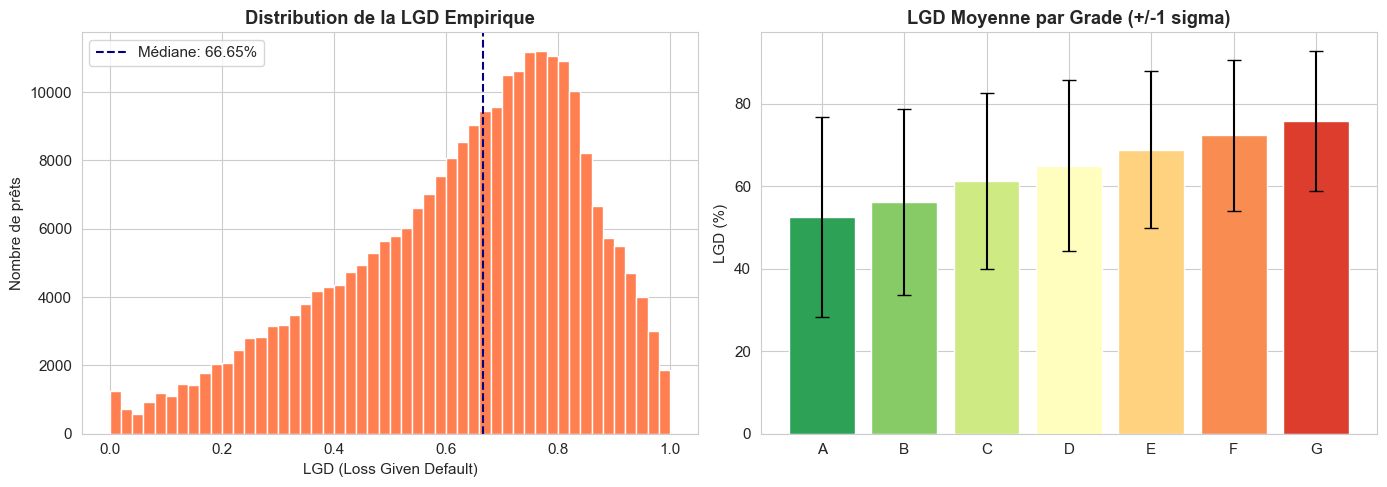


LGD par grade (%) :
        mean  median    std
grade                      
A      52.43   54.15  24.20
B      56.12   58.57  22.57
C      61.27   65.08  21.28
D      64.94   69.09  20.67
E      68.84   73.04  19.05
F      72.28   76.54  18.32
G      75.72   79.29  16.90


In [15]:
# Calcul LGD empirique sur les prêts défaillants
defaulted = df_raw[df_raw['default_flag'] == 1].copy()
defaulted['recovery_rate'] = (
    (defaulted['total_rec_prncp'].fillna(0) + defaulted['recoveries'].fillna(0))
    / defaulted['funded_amnt'].replace(0, np.nan)
).clip(0, 1)
defaulted['LGD'] = 1 - defaulted['recovery_rate']

print(f'Prêts défaillants analysés : {len(defaulted):,}')
print(f'LGD médiane globale        : {defaulted["LGD"].median():.2%}')
print(f'LGD moyenne globale        : {defaulted["LGD"].mean():.2%}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution LGD
axes[0].hist(defaulted['LGD'].dropna(), bins=50, color='coral', edgecolor='white')
axes[0].axvline(defaulted['LGD'].median(), color='navy', linestyle='--',
                label=f"Médiane: {defaulted['LGD'].median():.2%}")
axes[0].set_title('Distribution de la LGD Empirique', fontweight='bold')
axes[0].set_xlabel('LGD (Loss Given Default)')
axes[0].set_ylabel('Nombre de prêts')
axes[0].legend()

# LGD par grade
lgd_grade = defaulted.groupby('grade')['LGD'].agg(['mean', 'median', 'std'])
lgd_grade = lgd_grade.reindex(['A','B','C','D','E','F','G'])
x = range(len(lgd_grade))
axes[1].bar(x, lgd_grade['mean'] * 100, color=PALETTE, label='LGD Moyenne', edgecolor='white')
axes[1].errorbar(x, lgd_grade['mean'] * 100, yerr=lgd_grade['std'] * 100,
                  fmt='none', color='black', capsize=5, linewidth=1.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(lgd_grade.index)
axes[1].set_title('LGD Moyenne par Grade (+/-1 sigma)', fontweight='bold')
axes[1].set_ylabel('LGD (%)')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_11_lgd_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nLGD par grade (%) :')
print((lgd_grade * 100).round(2))

---
## Conclusion de l'EDA

### Observations clés

| Variable | Observation | Impact modélisation |
|---|---|---|
| `grade` | Gradient clair A→G : DR passe de ~3% à ~30% | Feature PD #1 |
| `int_rate` | Fortement corrélé à grade (r≈0.95) | Redondance à surveiller |
| `dti` | Distribution asymétrique, outliers > 40% | Cap au 99e percentile |
| `annual_inc` | Distribution log-normale, outliers > $1M | Log-transformation + cap |
| `revol_util` | 2-3% de valeurs > 100% (erreur saisie) | Cap à 100% |
| UNRATE | Corrélation visuelle forte avec DR trimestriel | Driver satellite PD |
| LGD | Grade A ≈ 50%, Grade G ≈ 75% | Gradient attendu validé |
| Stage 3 | 11,6% du portefeuille = défauts réels | Déséquilibre classes |

### Décisions de preprocessing (Notebook 02)
- **Outliers** : cap annual_inc/dti au 99e percentile, revol_util à 100%
- **Imputation** : médiane par grade pour dti/revol_util, 0 pour délinquances
- **Encodage** : grade ordinal 1-7, sub_grade 1-35, emp_length str→int
- **Dates** : parsing format `%b-%Y`, calcul `credit_age_months`
- **SMOTE / class_weight** : gérer 7% de défauts dans le modèle PD

> **Prochain notebook :** `02_Preprocessing.ipynb` — Pipeline complet → `loan_clean.parquet`

## Coherence avec la chaine IFRS 9 + Bale + stress testing

Ce notebook s'inscrit dans la chaine complete:

`Donnees -> Qualite -> PD/LGD/EAD -> ECL IFRS 9 -> Satellites macro -> Stress Y1 -> RWA/CET1 -> Decision -> Gouvernance`

Les resultats finaux de niveau bancaire sont consolides dans:

- `notebooks/08_Banking_Expert_Review.ipynb`
- `outputs/results/one_year_stress_decision_matrix.csv`
- `outputs/results/basel_capital_metrics.csv`
- `outputs/results/regulatory_segment_summary.csv`
- `outputs/results/dynamic_projection_expert.csv`

Cette coherence permet de defendre le projet a la fois comme travail de modelisation
et comme prototype de plateforme bancaire.